In [1]:
import os
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
np.random.seed(42)
os.makedirs("../report/figures", exist_ok=True)

def save(name):
    plt.savefig(f"../report/figures/{name}.png", dpi=150, bbox_inches="tight")

red = pd.read_csv("../data/raw/winequality-red.csv", sep=";")
white = pd.read_csv("../data/raw/winequality-white.csv", sep=";")
red["type"] = "red"
white["type"] = "white"
df = pd.concat([red, white], ignore_index=True)

In [2]:
print(df.shape)
df.info()
print(df.head())
print("Missing:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(df["type"].value_counts())

(6497, 13)
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB
   fixed acidity  volatile acidity  citric acid  residual sugar  ch

In [3]:
num = df.drop(columns="type")
summary = num.describe().T
summary["median"] = num.median()
summary["IQR"] = num.quantile(0.75) - num.quantile(0.25)
summary["skew"] = num.skew()
summary["kurtosis"] = num.kurt()
summary["CV_%"] = (num.std() / num.mean() * 100)
print(summary.round(2))
print(df.groupby("type").mean(numeric_only=True).T.round(2))

                       count    mean    std   min    25%     50%     75%  \
fixed acidity         6497.0    7.22   1.30  3.80   6.40    7.00    7.70   
volatile acidity      6497.0    0.34   0.16  0.08   0.23    0.29    0.40   
citric acid           6497.0    0.32   0.15  0.00   0.25    0.31    0.39   
residual sugar        6497.0    5.44   4.76  0.60   1.80    3.00    8.10   
chlorides             6497.0    0.06   0.04  0.01   0.04    0.05    0.06   
free sulfur dioxide   6497.0   30.53  17.75  1.00  17.00   29.00   41.00   
total sulfur dioxide  6497.0  115.74  56.52  6.00  77.00  118.00  156.00   
density               6497.0    0.99   0.00  0.99   0.99    0.99    1.00   
pH                    6497.0    3.22   0.16  2.72   3.11    3.21    3.32   
sulphates             6497.0    0.53   0.15  0.22   0.43    0.51    0.60   
alcohol               6497.0   10.49   1.19  8.00   9.50   10.30   11.30   
quality               6497.0    5.82   0.87  3.00   5.00    6.00    6.00   

           

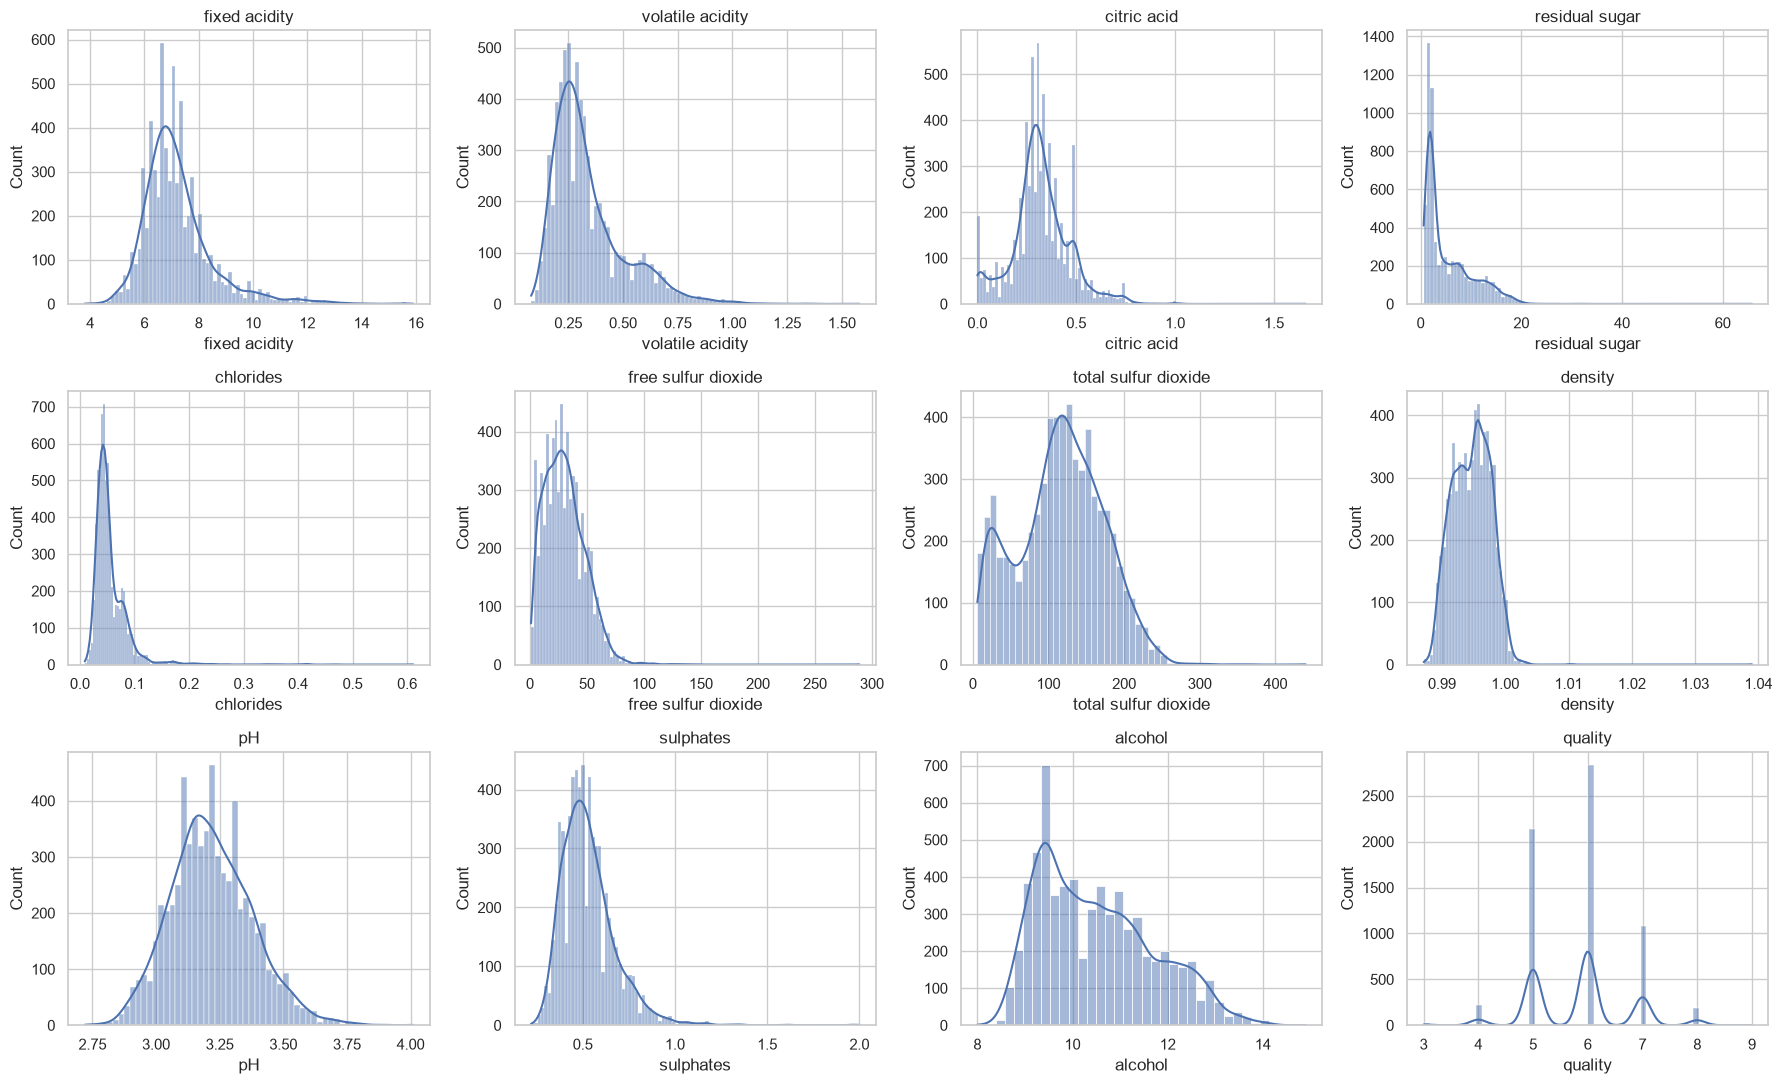

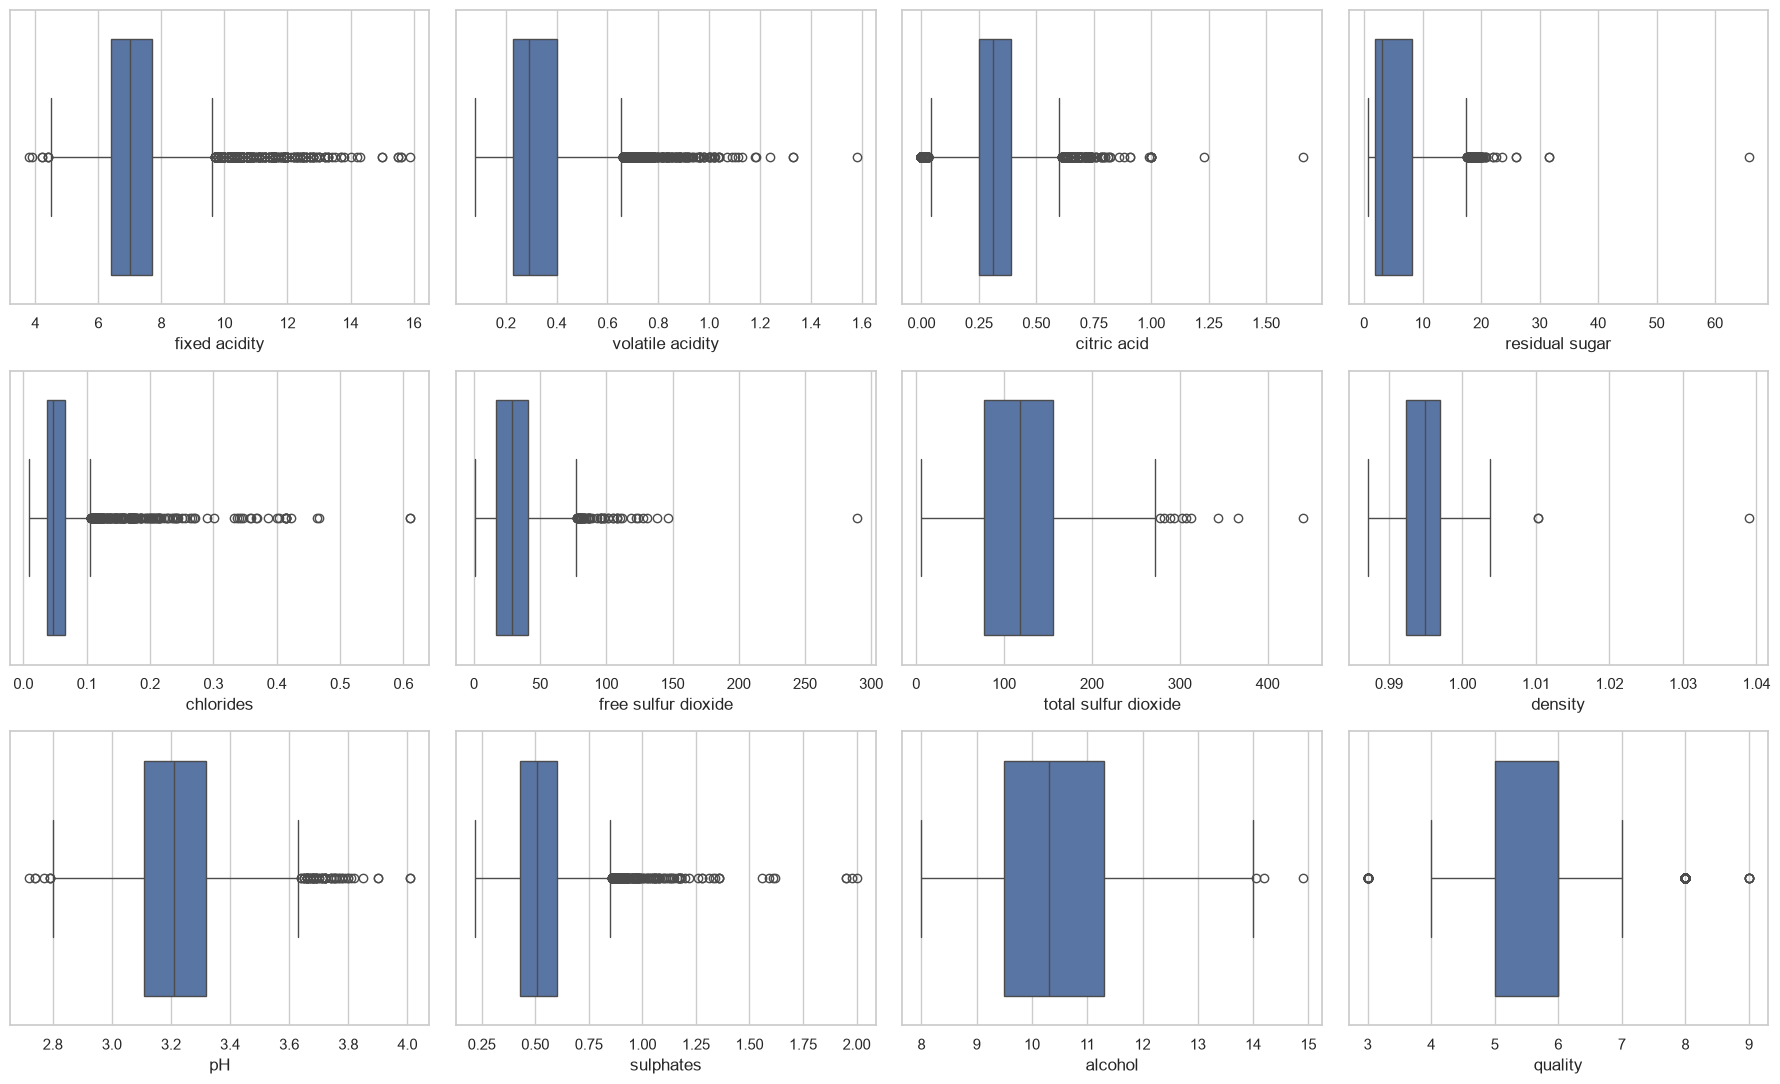

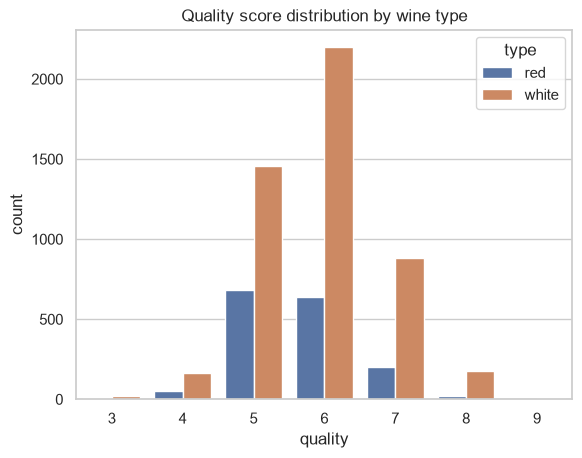

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), num.columns):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); save("histograms"); plt.show()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), num.columns):
    sns.boxplot(x=df[col], ax=ax)
plt.tight_layout(); save("boxplots"); plt.show()

sns.countplot(x="quality", data=df, hue="type")
plt.title("Quality score distribution by wine type"); save("quality_counts"); plt.show()

In [5]:
out = {}
for col in num.columns:
    q1, q3 = num[col].quantile([0.25, 0.75])
    i = q3 - q1
    out[col] = int(((num[col] < q1 - 1.5*i) | (num[col] > q3 + 1.5*i)).sum())
print(pd.Series(out).sort_values(ascending=False))

citric acid             509
volatile acidity        377
fixed acidity           357
chlorides               286
quality                 228
sulphates               191
residual sugar          118
pH                       73
free sulfur dioxide      62
total sulfur dioxide     10
density                   3
alcohol                   3
dtype: int64


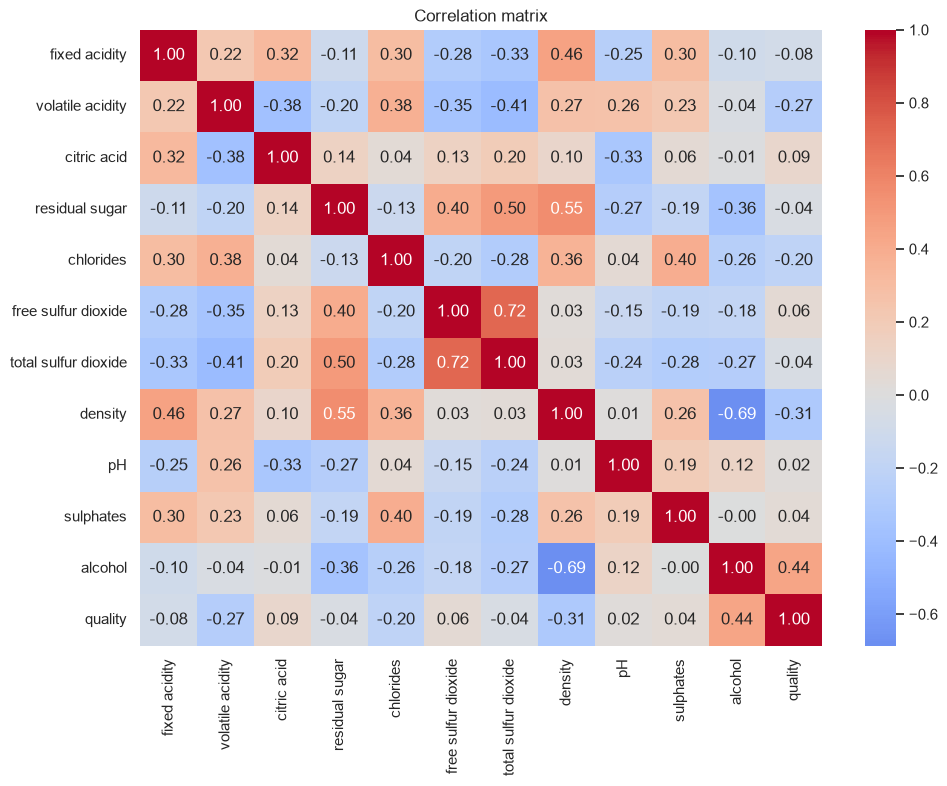

alcohol                 0.444319
citric acid             0.085532
free sulfur dioxide     0.055463
sulphates               0.038485
pH                      0.019506
residual sugar         -0.036980
total sulfur dioxide   -0.041385
fixed acidity          -0.076743
chlorides              -0.200666
volatile acidity       -0.265699
density                -0.305858
Name: quality, dtype: float64


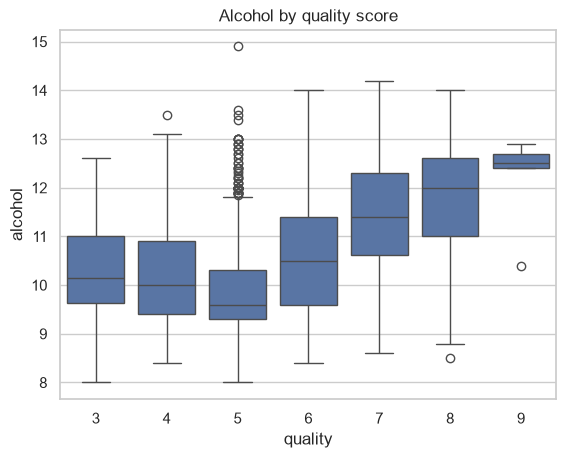

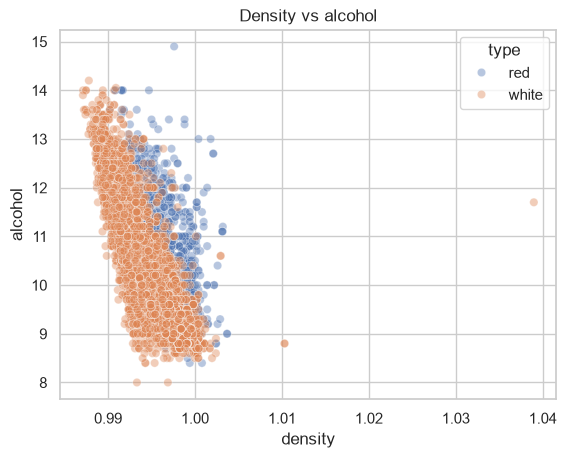

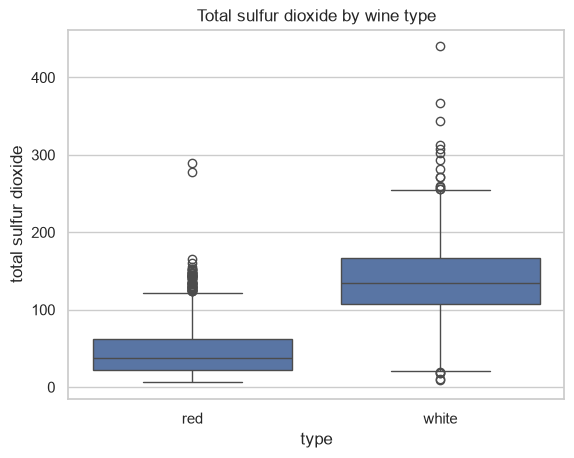

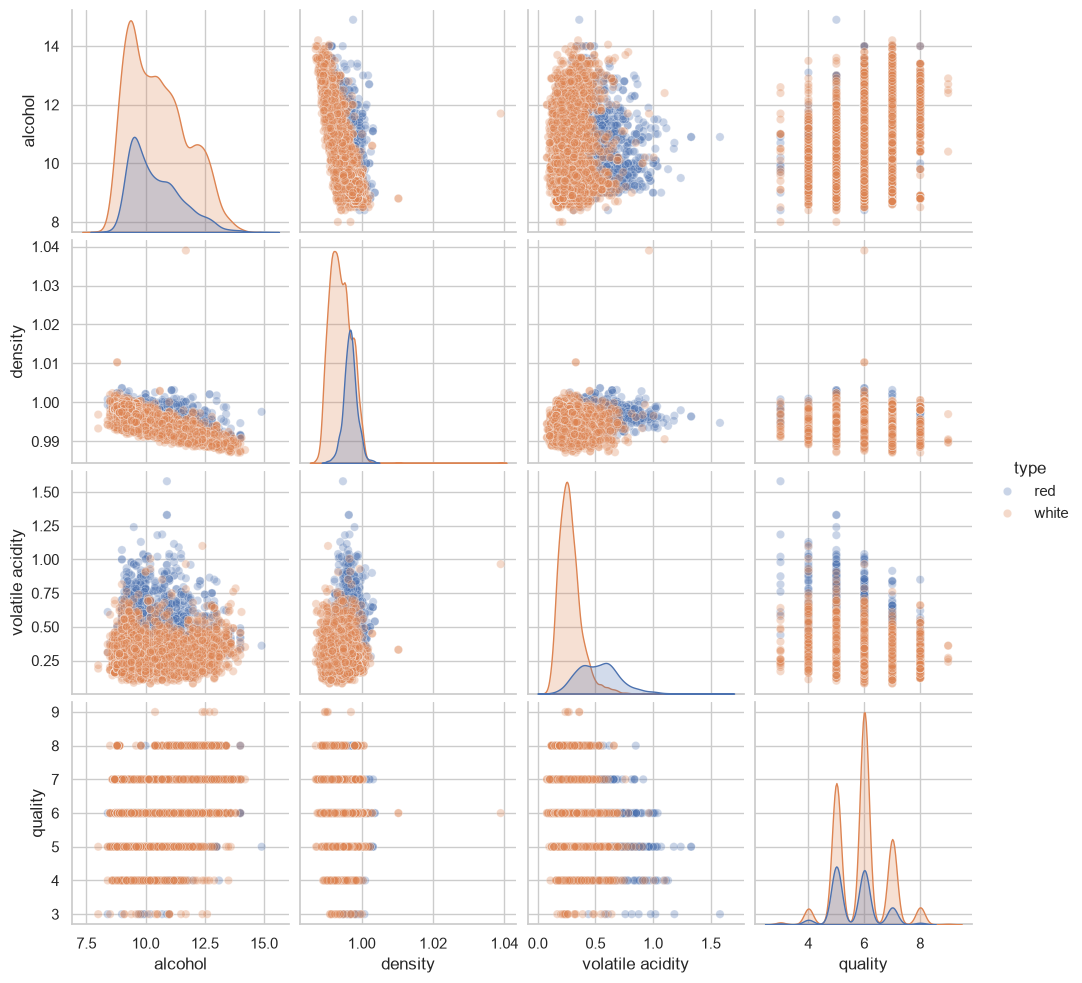

In [6]:
# Correlation heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); save("heatmap"); plt.show()

# Strongest correlates of quality
print(num.corr()["quality"].drop("quality").sort_values(ascending=False))

# Quality vs key variables
sns.boxplot(x="quality", y="alcohol", data=df)
plt.title("Alcohol by quality score"); save("alcohol_vs_quality"); plt.show()

# Relationship between two predictors
sns.scatterplot(x="density", y="alcohol", hue="type", data=df, alpha=0.4)
plt.title("Density vs alcohol"); save("density_alcohol"); plt.show()

# Red vs white comparison
sns.boxplot(x="type", y="total sulfur dioxide", data=df)
plt.title("Total sulfur dioxide by wine type"); save("so2_by_type"); plt.show()

# Pairplot of a few key variables (slow on large data, so keep it small)
sns.pairplot(df[["alcohol", "density", "volatile acidity", "quality", "type"]], hue="type",
             plot_kws={"alpha": 0.3})
save("pairplot"); plt.show()

In [7]:
# Check normality first (assumption check)
print(stats.normaltest(df["alcohol"]))

# Test 1: Is alcohol correlated with quality?
r, p = stats.pearsonr(df["alcohol"], df["quality"])
rho, p_s = stats.spearmanr(df["alcohol"], df["quality"])
print(f"Pearson r={r:.3f}, p={p:.2e} | Spearman rho={rho:.3f}, p={p_s:.2e}")

# Test 2: Do red and white wines differ in mean quality? (Welch t-test)
t, p = stats.ttest_ind(red["quality"], white["quality"], equal_var=False)
print(f"t={t:.3f}, p={p:.2e}")
print("Mann-Whitney:", stats.mannwhitneyu(red["quality"], white["quality"]))

# Test 3: Does mean alcohol differ across quality groups? (ANOVA)
df["quality_group"] = pd.cut(df["quality"], [0, 5, 6, 10], labels=["low", "medium", "high"])
groups = [g["alcohol"].values for _, g in df.groupby("quality_group", observed=True)]
f, p = stats.f_oneway(*groups)
print(f"F={f:.2f}, p={p:.2e}")
print("Kruskal-Wallis:", stats.kruskal(*groups))

# Test 4: Is wine type associated with quality group? (Chi-square)
ct = pd.crosstab(df["type"], df["quality_group"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct); print(f"chi2={chi2:.2f}, dof={dof}, p={p:.2e}")

NormaltestResult(statistic=np.float64(449.96082969616225), pvalue=np.float64(1.9599603929023295e-98))
Pearson r=0.444, p=1.50e-312 | Spearman rho=0.447, p=0.00e+00
t=-10.149, p=8.17e-24
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(3311514.0), pvalue=np.float64(3.6343410707988e-23))
F=936.92, p=0.00e+00
Kruskal-Wallis: KruskalResult(statistic=np.float64(1367.1639383104189), pvalue=np.float64(1.3308308734008998e-297))
quality_group   low  medium  high
type                             
red             744     638   217
white          1640    2198  1060
chi2=102.70, dof=2, p=5.01e-23


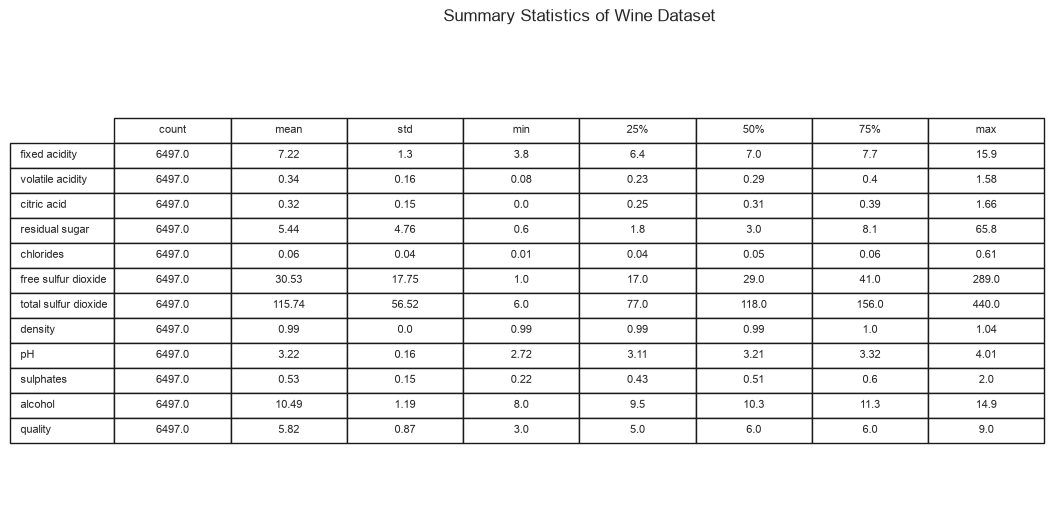

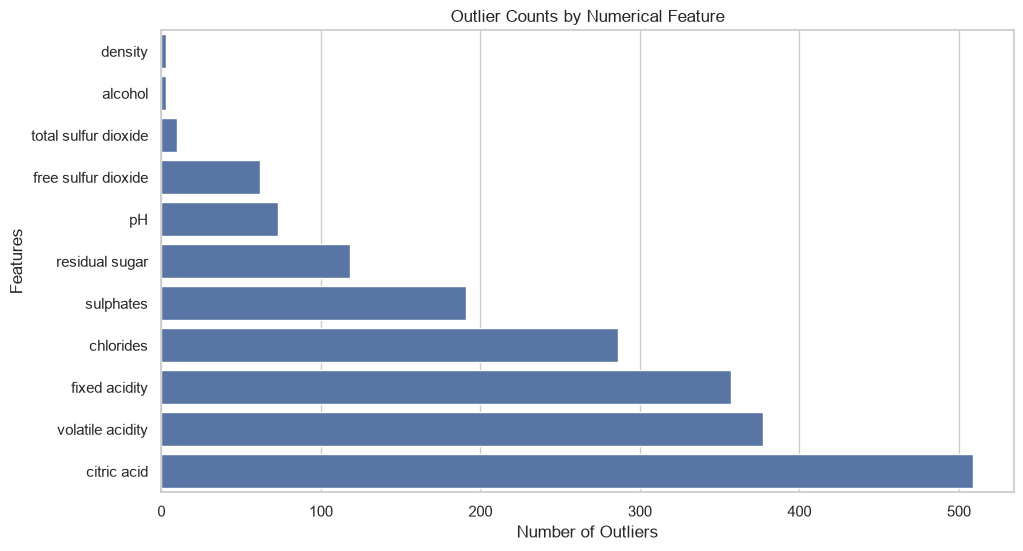

In [9]:
# Summary statistics table
summary = df.describe().round(2).T

fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

table = ax.table(
    cellText=summary.values,
    rowLabels=summary.index,
    colLabels=summary.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.5)

plt.title("Summary Statistics of Wine Dataset", pad=20)

save("summary_table")
plt.show()

# Outlier counts using IQR method

outlier_counts = {}

for col in num.drop(columns=["quality"], errors="ignore").columns:

    Q1 = num[col].quantile(0.25)
    Q3 = num[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((num[col] < lower) | (num[col] > upper)).sum()

    outlier_counts[col] = count

# Convert to Series
outlier_counts = pd.Series(outlier_counts).sort_values()

# Plot
plt.figure(figsize=(11, 6))

sns.barplot(
    x=outlier_counts.values,
    y=outlier_counts.index
)

plt.title("Outlier Counts by Numerical Feature")
plt.xlabel("Number of Outliers")
plt.ylabel("Features")

save("outlier_counts")
plt.show()

In [13]:
red = df.loc[df["type"].str.lower() == "red", "quality"].dropna()
white = df.loc[df["type"].str.lower() == "white", "quality"].dropna()

# Welch t-test
welch_stat, welch_p = stats.ttest_ind(
    red, white, equal_var=False
)

# Mann-Whitney U test
mw_stat, mw_p = stats.mannwhitneyu(
    red, white, alternative="two-sided"
)

print("Welch t-statistic:", welch_stat)
print("Welch p-value:", welch_p)

print("Mann-Whitney U statistic:", mw_stat)
print("Mann-Whitney p-value:", mw_p)

Welch t-statistic: -10.149363059143164
Welch p-value: 8.168348870049669e-24
Mann-Whitney U statistic: 3311514.0
Mann-Whitney p-value: 3.6343410707988e-23
